In [142]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
base_2025 = pd.read_excel("Datasets\preco_maca_2025.xlsx")
base_2026 = pd.read_excel("Datasets\preco_maca_2026.xlsx")
base_completa = pd.concat([base_2025, base_2026], ignore_index=True)

In [143]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [144]:
base_completa["Período"] = base_completa["Data da Coleta"].dt.to_period("Q")
base_completa

,Data da Coleta,Mês,Preço (R$),Período
0,2025-01-08,Janeiro,115.0,2025Q1
1,2025-01-15,Janeiro,112.5,2025Q1
2,2025-01-22,Janeiro,108.0,2025Q1
3,2025-01-29,Janeiro,105.0,2025Q1
4,2025-02-05,Fevereiro,98.0,2025Q1
...,...,...,...,...
90,2026-10-07,Outubro,168.0,2026Q4
91,2026-10-14,Outubro,170.0,2026Q4
92,2026-10-21,Outubro,172.0,2026Q4
93,2026-10-28,Outubro,175.0,2026Q4


In [145]:
base_completa["Data da Coleta"] = pd.to_datetime(base_completa["Data da Coleta"])
base_completa["Ano"] = base_completa["Data da Coleta"].dt.year
base_completa["Trimestre"] = base_completa["Data da Coleta"].dt.quarter

media_trimestre = base_completa.groupby(["Ano", "Trimestre"])["Preço (R$)"].mean().reset_index()
base_completa


,Data da Coleta,Mês,Preço (R$),Período,Ano,Trimestre
0,2025-01-08,Janeiro,115.0,2025Q1,2025,1
1,2025-01-15,Janeiro,112.5,2025Q1,2025,1
2,2025-01-22,Janeiro,108.0,2025Q1,2025,1
3,2025-01-29,Janeiro,105.0,2025Q1,2025,1
4,2025-02-05,Fevereiro,98.0,2025Q1,2025,1
...,...,...,...,...,...,...
90,2026-10-07,Outubro,168.0,2026Q4,2026,4
91,2026-10-14,Outubro,170.0,2026Q4,2026,4
92,2026-10-21,Outubro,172.0,2026Q4,2026,4
93,2026-10-28,Outubro,175.0,2026Q4,2026,4


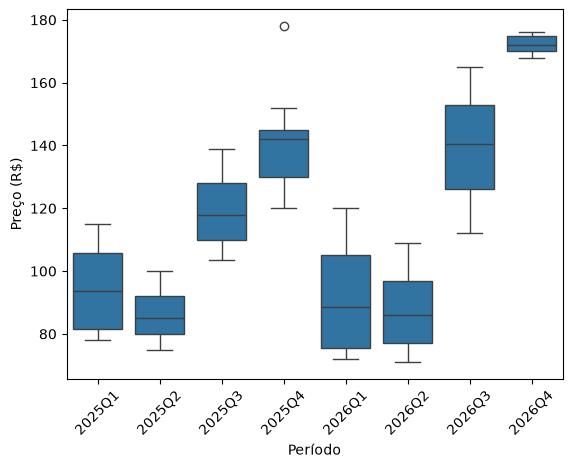

In [146]:
sns.boxplot(
    data = base_completa,
    x = "Período",
    y = "Preço (R$)"
)
plt.xticks(rotation=45)
plt.show()

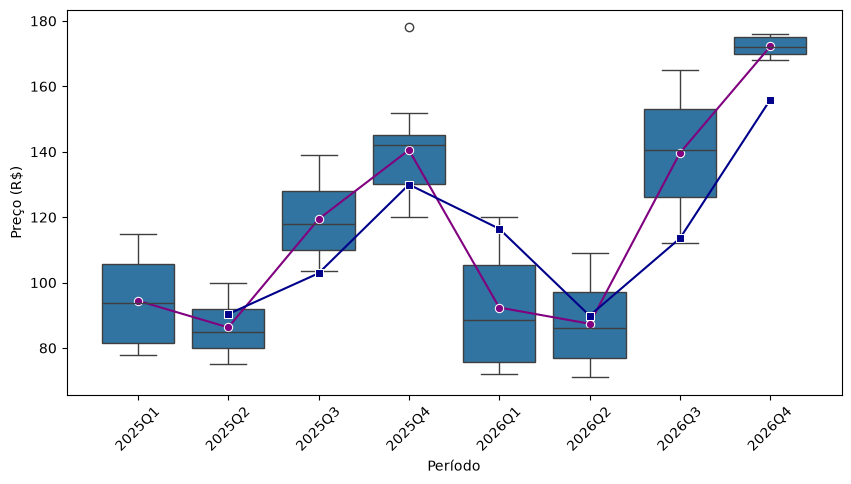

In [147]:
df_trimestral = (
    base_completa.groupby("Período")["Preço (R$)"]
    .mean()
    .reset_index()
    .sort_values("Período")
)
df_trimestral["media_movel"] = df_trimestral["Preço (R$)"].rolling(window=2).mean()
df_trimestral["Período"] = df_trimestral["Período"].astype(str)
plt.figure(figsize=(10, 5))
sns.boxplot(
    data = base_completa ,
    x = "Período",
    y = "Preço (R$)"
)
sns.lineplot(
    data = df_trimestral,
    x = "Período",
    y = "Preço (R$)",
    marker = "o", 
    color = "purple"
)

sns.lineplot(
    data = df_trimestral,
    x = "Período",
    y = "media_movel",
    marker = "s",
    color = "darkblue" 
)
plt.xticks(rotation=45)
plt.show()